# فاز ۱ — شناخت داده و آمار توصیفی (مسیر ج: NACC، MRI + UDS)

**سؤال پروژه:** آیا میانگین ضخامت قشر انتورینال (MRI) میان گروه‌های شناختی (نرمال، MCI، دمانس) تفاوت دارد و چه رابطه‌ای با نمره‌ی MoCA دارد، با در نظر گرفتن سن؟

## ۰. آماده‌سازی

In [15]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = os.environ.get("DATA_DIR", "/content")
OUT_DIR = "reports/phase1"
os.makedirs(f"{OUT_DIR}/tables", exist_ok=True)
os.makedirs(f"{OUT_DIR}/figures", exist_ok=True)

## ۱. نگاه اولیه

In [16]:
uds = pd.read_csv(f"{DATA_DIR}/udslong_imputed.csv")
mri = pd.read_csv(f"{DATA_DIR}/mriscanclean.csv")
adj = pd.read_csv(f"{DATA_DIR}/combined_adjacency_matrix.csv", index_col=0)

for name, d in [("UDS", uds), ("MRI", mri), ("Adjacency", adj)]:
    print(f"{name:10s} سطر = {d.shape[0]:5d}   ستون = {d.shape[1]:4d}")

UDS        سطر =  1237   ستون =  180
MRI        سطر =  1237   ستون =  126
Adjacency  سطر =    62   ستون =   62


In [17]:
# پنج سطر اول و ۱۲ ستون اول UDS
display(uds.iloc[:5, :12])
# پنج سطر اول و ۷ ستون اول MRI
display(mri.iloc[:5, :7])

,NACCID,SEX,HISPANIC,HISPOR,RACE,PRIMLANG,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,NACCNIHR
0,NACC359836,1.0,0.0,88.0,1.0,1.0,18.0,1.0,2.0,1.0,1.0,1.0
1,NACC990210,2.0,0.0,88.0,1.0,1.0,16.0,1.0,2.0,1.0,1.0,1.0
2,NACC074744,1.0,0.0,88.0,1.0,1.0,20.0,1.0,2.0,1.0,1.0,1.0
3,NACC083525,1.0,0.0,88.0,1.0,1.0,16.0,1.0,2.0,1.0,1.0,1.0
4,NACC092141,2.0,0.0,88.0,1.0,1.0,14.0,1.0,2.0,1.0,1.0,1.0


,NACCID,LH_CAUDALANTERIORCINGULATE_GVOL,RH_CAUDALANTERIORCINGULATE_GVOL,LH_CAUDALANTERIORCINGULATE_AVGTH,RH_CAUDALANTERIORCINGULATE_AVGTH,LH_CAUDALMIDDLEFRONTAL_GVOL,RH_CAUDALMIDDLEFRONTAL_GVOL
0,NACC359836,3462,2257,2.328,2.278,6767,5857
1,NACC990210,3131,2528,2.553,2.292,6898,6880
2,NACC074744,2463,1618,2.060,1.942,7176,5770
3,NACC083525,2980,2302,2.405,2.230,6915,6303
4,NACC092141,3000,1703,2.404,2.140,6655,6556


In [18]:
print("نوع ستون‌ها در UDS:\n", uds.dtypes.value_counts(), "\n")
print("نوع ستون‌ها در MRI:\n", mri.dtypes.value_counts(), "\n")
print("تعداد سلول‌های NaN خام -> UDS:", uds.isna().sum().sum(), "| MRI:", mri.isna().sum().sum())

نوع ستون‌ها در UDS:
 float64    179
object       1
Name: count, dtype: int64 

نوع ستون‌ها در MRI:
 int64      63
float64    62
object      1
Name: count, dtype: int64 

تعداد سلول‌های NaN خام -> UDS: 0 | MRI: 0


## ۲. شناسه‌ها، واحد مشاهده و ادغام (تکلیف‌های ج.۲ و ج.۳)

In [19]:
for name, d in [("UDS", uds), ("MRI", mri)]:
    print(f"{name}: سطر={len(d)}  NACCID یکتا={d.NACCID.nunique()}  تکراری={d.NACCID.duplicated().sum()}")

ids_u, ids_m = set(uds.NACCID), set(mri.NACCID)
print("\nدر هر دو فایل:", len(ids_u & ids_m), "| فقط UDS:", len(ids_u - ids_m), "| فقط MRI:", len(ids_m - ids_u))

rows_per = uds.groupby("NACCID").size().value_counts().rename_axis("سطر به ازای هر شرکت‌کننده").reset_index(name="تعداد شرکت‌کننده")
display(rows_per)

UDS: سطر=1237  NACCID یکتا=1237  تکراری=0
MRI: سطر=1237  NACCID یکتا=1237  تکراری=0

در هر دو فایل: 1237 | فقط UDS: 0 | فقط MRI: 0


,سطر به ازای هر شرکت‌کننده,تعداد شرکت‌کننده
0,1,1237


In [20]:
# NACCUDSD در هر دو فایل هست؛ قبل از حذف یک نسخه، مطمئن می‌شویم یکی‌اند
chk = uds[["NACCID", "NACCUDSD"]].merge(mri[["NACCID", "NACCUDSD"]], on="NACCID", suffixes=("_uds", "_mri"))
print("توافق NACCUDSD بین دو فایل:", (chk.NACCUDSD_uds == chk.NACCUDSD_mri).mean())

# ادغام یک‌به‌یک روی NACCID
df = uds.merge(mri.drop(columns="NACCUDSD"), on="NACCID", how="inner", validate="one_to_one").copy()

flow = pd.DataFrame({
    "مرحله": ["سطرهای UDS", "شرکت‌کننده‌ی یکتا در UDS", "سطرهای MRI", "شرکت‌کننده‌ی یکتا در MRI",
              "مشترک (ادغام)", "فقط UDS", "فقط MRI"],
    "n": [len(uds), uds.NACCID.nunique(), len(mri), mri.NACCID.nunique(),
          len(df), len(ids_u - ids_m), len(ids_m - ids_u)]})
display(flow)
flow.to_csv(f"{OUT_DIR}/tables/01_merge_flow.csv", index=False)

توافق NACCUDSD بین دو فایل: 1.0


,مرحله,n
0,سطرهای UDS,1237
1,شرکت‌کننده‌ی یکتا در UDS,1237
2,سطرهای MRI,1237
3,شرکت‌کننده‌ی یکتا در MRI,1237
4,مشترک (ادغام),1237
5,فقط UDS,0
6,فقط MRI,0


## ۳. نقشه‌ی متغیرها (تکلیف ج.۱)

In [21]:
cols = list(uds.columns)
def span(a, b):
    return cols[cols.index(a): cols.index(b) + 1]

groups = {
"شناسه یکتای شرکت‌کننده (NACC Derived ID)": (
        "شناسه",
        ["NACCID"]
    ),
    "فرم A1: اطلاعات جمعیت‌شناختی شرکت‌کننده (Subject Demographics)": (
        "جمعیت‌شناختی",
        span("SEX", "NACCAGE")
    ),
    "فرم A3 + ژنتیک: سابقه خانوادگی و ژنوتیپ APOE (Family History & RDD-Genetics)": (
        "پزشکی",
        span("NACCFAM", "NACCFFTD") + ["NACCAPOE"]
    ),
    "فرم A4: داروهای مصرفی شرکت‌کننده (Subject Medications - NACC Derived)": (
        "پزشکی",
        ["ANYMEDS"] + span("NACCAAAS", "NACCVASD")
    ),
    "فرم A5: سابقه سلامت و سبک زندگی (Subject Health History)": (
        "پزشکی",
        span("TOBAC30", "PSYCDIS")
    ),
    "فرم B1: اندازه‌گیری‌های فیزیکی و حسی (Evaluation Form - Physical)": (
        "پزشکی",
        span("HEIGHT", "NACCBMI")
    ),
    "فرم B2: معاینه عصبی بالینی (Neurological Examination Findings)": (
        "پزشکی",
        ["NACCNREX", "NORMEXAM"]
    ),
    "فرم B5: پرسش‌نامه علائم عصب‌روان‌شناختی (Neuropsychiatric Inventory - NPI-Q)": (
        "پزشکی",
        span("NPIQINF", "APPSEV")
    ),
    "فرم B6: مقیاس افسردگی سالمندان (Geriatric Depression Scale - GDS)": (
        "پزشکی",
        span("NOGDS", "NACCGDS")
    ),
    "فرم B7: پرسش‌نامه فعالیت‌های عملکردی روزمره (Functional Activities Questionnaire - FAQ)": (
        "عملکردی",
        span("BILLS", "TRAVEL")
    ),
    "فرم B9 + B4: قضاوت بالینی علائم و مقیاس شدت زوال عقل (Clinician Judgment & CDR®)": (
        "شناختی",
        ["DECSUB"] + span("MEMORY", "CDRGLOB")
    ),
    "فرم C2: بسته آزمون‌های عصب‌روان‌شناختی عینی (Neuropsychological Battery - MoCA/TMT/Fluency)": (
        "شناختی",
        ["ANIMALS", "VEG", "TRAILA", "TRAILARR", "TRAILALI", "TRAILB", "TRAILBRR", "TRAILBLI", "MOCATOTS"]
    ),
    "فرم D1: تشخیص بالینی وضعیت شناختی (Clinician Diagnosis - Cognitive Status)": (
        "تشخیصی",
        ["NACCUDSD"]
    ),
}

rows = [{"دسته کلان ": macro, "زیرگروه (فرم NACC)": sub, "متغیر": v}
        for sub, (macro, vs) in groups.items() for v in vs]
vmap = pd.DataFrame(rows).drop_duplicates("متغیر")

unmapped = [c for c in cols if c not in set(vmap["متغیر"])]
print(f"ستون‌های UDS: {len(cols)} | دسته‌بندی‌شده: {len(vmap)} | جامانده: {unmapped}")

summary_table = (vmap.groupby(["دسته کلان ", "زیرگروه (فرم NACC)"], sort=False)
                 .size().reset_index(name="تعداد متغیر"))
display(summary_table)
display(vmap.groupby("دسته کلان ", sort=False).size().rename("جمع به تفکیک دسته‌ی کلان").to_frame())
vmap.to_csv(f"{OUT_DIR}/tables/02_uds_variable_map.csv", index=False)

ستون‌های UDS: 180 | دسته‌بندی‌شده: 180 | جامانده: []


,دسته کلان,زیرگروه (فرم NACC),تعداد متغیر
0,شناسه,شناسه یکتای شرکت‌کننده (NACC Derived ID),1
1,جمعیت‌شناختی,فرم A1: اطلاعات جمعیت‌شناختی شرکت‌کننده (Subje...,12
2,پزشکی,فرم A3 + ژنتیک: سابقه خانوادگی و ژنوتیپ APOE (...,12
3,پزشکی,فرم A4: داروهای مصرفی شرکت‌کننده (Subject Medi...,21
4,پزشکی,فرم A5: سابقه سلامت و سبک زندگی (Subject Healt...,49
5,پزشکی,فرم B1: اندازه‌گیری‌های فیزیکی و حسی (Evaluati...,12
6,پزشکی,فرم B2: معاینه عصبی بالینی (Neurological Exami...,2
7,پزشکی,فرم B5: پرسش‌نامه علائم عصب‌روان‌شناختی (Neuro...,25
8,پزشکی,فرم B6: مقیاس افسردگی سالمندان (Geriatric Depr...,17
9,عملکردی,فرم B7: پرسش‌نامه فعالیت‌های عملکردی روزمره (F...,10


,جمع به تفکیک دسته‌ی کلان
دسته کلان,
شناسه,1
جمعیت‌شناختی,12
پزشکی,138
عملکردی,10
شناختی,18
تشخیصی,1


In [22]:
# نقشه‌ی ۱۲۴ متغیر MRI: نیمکره × ناحیه × نوع اندازه‌گیری
mri_feature_cols = [c for c in mri.columns if c not in ["NACCID", "NACCUDSD"]]
mri_map_rows = []
for col in mri_feature_cols:
    hemi = "نیمکره چپ (LH)" if col.startswith("LH_") else "نیمکره راست (RH)"
    metric = "حجم ماده خاکستری (GVOL)" if col.endswith("_GVOL") else "ضخامت میانگین قشر (AVGTH)"
    roi = col.replace("LH_", "").replace("RH_", "").replace("_GVOL", "").replace("_AVGTH", "")
    mri_map_rows.append({"متغیر": col, "ناحیه (ROI)": roi, "نیمکره": hemi, "نوع اندازه‌گیری": metric})
mri_vmap = pd.DataFrame(mri_map_rows)

print(f"ویژگی‌های MRI: {len(mri_vmap)} | ناحیه‌ی یکتا: {mri_vmap['ناحیه (ROI)'].nunique()}")
display(pd.crosstab(mri_vmap["نیمکره"], mri_vmap["نوع اندازه‌گیری"], margins=True, margins_name="مجموع"))
mri_vmap.to_csv(f"{OUT_DIR}/tables/02_mri_variable_map.csv", index=False)

# ماتریس مجاورت: ابعاد، تقارن، قطر، تعداد یال‌ها (بدون قطر) و تطابق نام نواحی با MRI
A = adj.values
n_diag = int(np.trace(A))
print("\nماتریس مجاورت:", A.shape, "| متقارن:", bool((A == A.T).all()), "| قطر همه ۱:", bool((np.diag(A) == 1).all()))
print("تعداد یال‌ها (بدون قطر):", int((A.sum() - n_diag) // 2))
norm = lambda s: s.lower().replace("_", "")
adj_rois = {norm(n.split("_", 1)[1]) for n in adj.index}
mri_rois = {norm(r) for r in mri_vmap["ناحیه (ROI)"]}
print("نواحی ماتریس مجاورت = نواحی MRI:", adj_rois == mri_rois)

ویژگی‌های MRI: 124 | ناحیه‌ی یکتا: 31


نوع اندازه‌گیری,حجم ماده خاکستری (GVOL),ضخامت میانگین قشر (AVGTH),مجموع
نیمکره,,,
نیمکره راست (RH),31,31,62
نیمکره چپ (LH),31,31,62
مجموع,62,62,124



ماتریس مجاورت: (62, 62) | متقارن: True | قطر همه ۱: True
تعداد یال‌ها (بدون قطر): 232
نواحی ماتریس مجاورت = نواحی MRI: True


# ۴. ممیزی کیفیت داده (تکلیف ۵ مشترک و ج.۴)

In [23]:
key = ["NACCAGE", "SEX", "EDUC", "NACCUDSD", "MOCATOTS", "CDRGLOB", "CDRSUM", "NACCAPOE", "NACCBMI", "NACCGDS", "TRAILA", "TRAILB"]
display(df[key].agg(["min", "max", "nunique"]).T)

print("مقادیر MoCA بالای ۳۰:", [float(x) for x in sorted(df.loc[df.MOCATOTS > 30, "MOCATOTS"].unique())])
print("تعداد MoCA غیرصحیح:", int((df.MOCATOTS % 1 != 0).sum()))

,min,max,nunique
NACCAGE,41.0,91.0,48.0
SEX,1.0,2.0,2.0
EDUC,0.0,99.0,23.0
NACCUDSD,1.0,4.0,4.0
MOCATOTS,0.0,88.0,72.0
CDRGLOB,0.0,2.0,4.0
CDRSUM,0.0,15.0,22.0
NACCAPOE,1.0,9.0,7.0
NACCBMI,15.6,888.8,239.0
NACCGDS,0.0,88.0,23.0


مقادیر MoCA بالای ۳۰: [30.8, 34.2, 38.8, 39.4, 88.0]
تعداد MoCA غیرصحیح: 249


In [24]:
audit = []
def flag(var, mask, rule):
    audit.append({"متغیر": var, "قاعده": rule, "n": int(mask.sum()), "درصد": round(100 * mask.mean(), 2)})
    return mask

# --- تصمیم‌های پاک‌سازی (همه‌ی تصمیم‌ها همین‌جا) ---
df["MOCA"] = df.MOCATOTS.copy()
m88 = flag("MOCATOTS", df.MOCATOTS == 88, "کد ۸۸ = اجرا نشده/نامعلوم -> NaN")
mhi = flag("MOCATOTS", (df.MOCATOTS > 30) & ~m88, "بالای ۳۰ غیرممکن است -> NaN")
df.loc[m88 | mhi, "MOCA"] = np.nan
flag("MOCATOTS", df.MOCATOTS % 1 != 0, "غیرصحیح (نشانه‌ی imputation)؛ نگه داشته شد، فقط گزارش")

df["EDU"] = df.EDUC.copy()
flag("EDUC", df.EDUC == 99, "کد ۹۹ = نامعلوم -> NaN")
df.loc[df.EDUC == 99, "EDU"] = np.nan

flag("NACCAPOE", df.NACCAPOE == 9, "کد ۹ = نامعلوم؛ به عنوان دسته‌ی جدا نگه داشته شد")
flag("NACCBMI", df.NACCBMI > 60, "کد/مقدار غیرمعقول (مثل ۸۸۸٫۸)؛ در تحلیل اصلی استفاده نمی‌شود")
flag("NACCGDS", df.NACCGDS > 15, "حداکثر GDS برابر ۱۵؛ در تحلیل اصلی استفاده نمی‌شود")
flag("TRAILA", df.TRAILA > 150, "کد ۹۹۸؛ در تحلیل اصلی استفاده نمی‌شود")
flag("TRAILB", df.TRAILB > 300, "کد ۹۹۸؛ در تحلیل اصلی استفاده نمی‌شود")
flag("NACCUDSD", df.NACCUDSD == 2, "گروه «مختل بدون MCI» خیلی کوچک است؛ از مقایسه‌ها کنار گذاشته می‌شود")
for c in ["LH_ENTORHINAL_AVGTH", "RH_ENTORHINAL_AVGTH", "LH_ENTORHINAL_GVOL", "RH_ENTORHINAL_GVOL"]:
    flag(c, df[c] <= 0, "صفر/منفی برای ناحیه‌ی اندازه‌گیری‌شده غیرممکن است")

audit_df = pd.DataFrame(audit)
display(audit_df)
audit_df.to_csv(f"{OUT_DIR}/tables/03_data_audit.csv", index=False)

# مورد صفرِ حجم: ضخامتش چیست؟
display(df.loc[df.LH_ENTORHINAL_GVOL <= 0, ["NACCID", "NACCUDSD", "LH_ENTORHINAL_GVOL", "LH_ENTORHINAL_AVGTH", "RH_ENTORHINAL_GVOL", "RH_ENTORHINAL_AVGTH"]])

# بررسی همه‌ی ۱۲۴ ستون MRI برای مقدار ≤ ۰
mri_meas = [c for c in mri.columns if c.endswith(("_GVOL", "_AVGTH"))]
neg = df[mri_meas].le(0)
bad = [(df.loc[i, "NACCID"], c, df.loc[i, c]) for i in df.index[neg.any(axis=1)] for c in neg.columns[neg.loc[i]]]
print("\nسلول‌های MRI با مقدار ≤ 0 در کل ۱۲۴ ستون:", len(bad))
display(pd.DataFrame(bad, columns=["NACCID", "متغیر", "مقدار"]))

,متغیر,قاعده,n,درصد
0,MOCATOTS,کد ۸۸ = اجرا نشده/نامعلوم -> NaN,4,0.32
1,MOCATOTS,بالای ۳۰ غیرممکن است -> NaN,5,0.40
2,MOCATOTS,غیرصحیح (نشانه‌ی imputation)؛ نگه داشته شد، فق...,249,20.13
3,EDUC,کد ۹۹ = نامعلوم -> NaN,2,0.16
4,NACCAPOE,کد ۹ = نامعلوم؛ به عنوان دسته‌ی جدا نگه داشته شد,278,22.47
5,NACCBMI,کد/مقدار غیرمعقول (مثل ۸۸۸٫۸)؛ در تحلیل اصلی ا...,131,10.59
6,NACCGDS,حداکثر GDS برابر ۱۵؛ در تحلیل اصلی استفاده نمی...,6,0.49
7,TRAILA,کد ۹۹۸؛ در تحلیل اصلی استفاده نمی‌شود,26,2.10
8,TRAILB,کد ۹۹۸؛ در تحلیل اصلی استفاده نمی‌شود,64,5.17
9,NACCUDSD,گروه «مختل بدون MCI» خیلی کوچک است؛ از مقایسه‌...,7,0.57


,NACCID,NACCUDSD,LH_ENTORHINAL_GVOL,LH_ENTORHINAL_AVGTH,RH_ENTORHINAL_GVOL,RH_ENTORHINAL_AVGTH
518,NACC931831,1.0,0,0.878,350,1.55



سلول‌های MRI با مقدار ≤ 0 در کل ۱۲۴ ستون: 2


,NACCID,متغیر,مقدار
0,NACC684612,LH_POSTERIORCINGULATE_GVOL,0
1,NACC931831,LH_ENTORHINAL_GVOL,0


In [25]:
print("۱. اثر مقادیر نامعتبر (>30) بر توزیع MoCA:")
print(f"   • قبل از پاک‌سازی (MOCATOTS خام): میانگین = {df.MOCATOTS.mean():.2f} | انحراف معیار = {df.MOCATOTS.std():.2f}")
print(f"   • بعد از پاک‌سازی (MOCA تمیز)   : میانگین = {df.MOCA.mean():.2f} | انحراف معیار = {df.MOCA.std():.2f}")

print("\n   وضعیت بالینی ۴ بیمار دارای کد ۸۸ در MoCA (اکثراً دمانس با CDR بالا):")
display(df.loc[df.MOCATOTS == 88, ["NACCID", "NACCUDSD", "CDRGLOB", "CDRSUM", "NACCAGE"]])

df["ENT_GVOL_MEAN"] = (df["LH_ENTORHINAL_GVOL"] + df["RH_ENTORHINAL_GVOL"]) / 2
df["ENT_THICK_MEAN"] = (df["LH_ENTORHINAL_AVGTH"] + df["RH_ENTORHINAL_AVGTH"]) / 2

sex_comp = (
    df.groupby(df["SEX"].map({1: "۱: مرد (سر بزرگ‌تر)", 2: "۲: زن"}))
    [["HEIGHT", "ENT_GVOL_MEAN", "ENT_THICK_MEAN"]]
    .mean()
    .round(3)
    .rename(columns={
        "HEIGHT": "میانگین قد (اینچ)",
        "ENT_GVOL_MEAN": "میانگین حجم انترورینال (mm³)",
        "ENT_THICK_MEAN": "میانگین ضخامت انترورینال (mm)"
    })
)
print("\n۲. مقایسه حساسیت حجم و ضخامت به جنسیت (در غیاب متغیر ICV):")
display(sex_comp)

۱. اثر مقادیر نامعتبر (>30) بر توزیع MoCA:
   • قبل از پاک‌سازی (MOCATOTS خام): میانگین = 24.65 | انحراف معیار = 5.75
   • بعد از پاک‌سازی (MOCA تمیز)   : میانگین = 24.39 | انحراف معیار = 4.42

   وضعیت بالینی ۴ بیمار دارای کد ۸۸ در MoCA (اکثراً دمانس با CDR بالا):


,NACCID,NACCUDSD,CDRGLOB,CDRSUM,NACCAGE
459,NACC597151,4.0,1.0,4.0,75.0
467,NACC670504,4.0,2.0,14.0,71.0
490,NACC792779,4.0,1.0,4.0,64.0
650,NACC969396,1.0,0.0,0.0,65.0



۲. مقایسه حساسیت حجم و ضخامت به جنسیت (در غیاب متغیر ICV):


,میانگین قد (اینچ),میانگین حجم انترورینال (mm³),میانگین ضخامت انترورینال (mm)
SEX,,,
۱: مرد (سر بزرگ‌تر),70.777,1657.711,3.003
۲: زن,66.322,1460.668,3.021


In [26]:
# --- بررسی سازگاری منطقی بین تشخیص بالینی CDRGLOB و MoCA ---
logic_df = pd.DataFrame({
    "شرط سازگاری منطقی": [
        "افراد نرمال با CDR کلی >= 1",
        "افراد دمانس با CDR کلی == 0",
        "افراد نرمال با CDR کلی == 0.5",
        "افراد دمانس با MoCA >= 24",
        "افراد نرمال با MoCA < 18",
    ],
    "تعداد": [
        int(((df.NACCUDSD == 1) & (df.CDRGLOB >= 1)).sum()),
        int(((df.NACCUDSD == 4) & (df.CDRGLOB == 0)).sum()),
        int(((df.NACCUDSD == 1) & (df.CDRGLOB == 0.5)).sum()),
        int(((df.NACCUDSD == 4) & (df.MOCA >= 24)).sum()),
        int(((df.NACCUDSD == 1) & (df.MOCA < 18)).sum()),
    ],
})
print("بخش ۵.۳ گزارش — سازگاری منطقی:")
display(logic_df)
logic_df.to_csv(f"{OUT_DIR}/tables/03b_logical_consistency.csv", index=False)

# --- گمشدگی و مقدار نامعتبر در متغیرهای اصلی دو وجه ---
t8_vars = [
    ("UDS", "MOCATOTS", df.MOCA.isna().sum(), "کد ۸۸ (۴ نفر) و مقدار >۳۰ (۵ نفر)"),
    ("UDS", "EDUC", df.EDU.isna().sum(), "کد ۹۹"),
    ("UDS", "NACCAGE", 0, "بازه منطقی ۱۸ تا ۱۱۰"),
    ("UDS", "SEX", 0, "کدهای ۱ و ۲"),
    ("UDS", "NACCUDSD", 0, "کدهای ۱ تا ۴"),
    ("MRI", "LH_ENTORHINAL_AVGTH", (df.LH_ENTORHINAL_AVGTH <= 0).sum(), "ضخامت > ۰"),
    ("MRI", "RH_ENTORHINAL_AVGTH", (df.RH_ENTORHINAL_AVGTH <= 0).sum(), "ضخامت > ۰"),
    ("MRI", "LH_ENTORHINAL_GVOL", (df.LH_ENTORHINAL_GVOL <= 0).sum(), "حجم صفر (غیرممکن)"),
    ("MRI", "RH_ENTORHINAL_GVOL", (df.RH_ENTORHINAL_GVOL <= 0).sum(), "حجم صفر (غیرممکن)"),
]
table8 = pd.DataFrame(t8_vars, columns=["وجه", "متغیر", "نامعتبر/نامعلوم", "توضیح"])
table8.insert(2, "NaN خام", 0)
table8["درصد"] = (100 * table8["نامعتبر/نامعلوم"] / len(df)).round(2)
print("\nگمشدگی و مقدار نامعتبر در متغیرهای اصلی دو وجه:")
display(table8)
table8.to_csv(f"{OUT_DIR}/tables/03c_table8_main_vars_missing.csv", index=False)


GROUP_LABELS_ALL = {1: "Normal cognition", 2: "Impaired, not MCI", 3: "MCI", 4: "Dementia"}
df["GROUP_ALL"] = df.NACCUDSD.map(GROUP_LABELS_ALL)

t9_rows = []
for g_code, g_name in GROUP_LABELS_ALL.items():
    sub = df[df.NACCUDSD == g_code]
    n_tot = len(sub)
    moca_inv = int(sub.MOCA.isna().sum())
    edu_inv = int(sub.EDU.isna().sum())
    moca_nonint = int((sub.MOCATOTS % 1 != 0).sum())
    t9_rows.append({
        "گروه": g_name,
        "تعداد": n_tot,
        "MoCA نامعتبر": moca_inv,
        "درصد MoCA نامعتبر": round(100 * moca_inv / n_tot, 2),
        "تحصیلات نامعلوم": edu_inv,
        "MoCA غیرصحیح": moca_nonint,
        "درصد غیرصحیح": round(100 * moca_nonint / n_tot, 1),
    })
table9 = pd.DataFrame(t9_rows)
print("\nحذف‌ها و مقادیر imputed به تفکیک گروه تشخیصی:")
display(table9)
table9.to_csv(f"{OUT_DIR}/tables/03d_table9_missing_by_group.csv", index=False)

بخش ۵.۳ گزارش — سازگاری منطقی:


,شرط سازگاری منطقی,تعداد
0,افراد نرمال با CDR کلی >= 1,0
1,افراد دمانس با CDR کلی == 0,0
2,افراد نرمال با CDR کلی == 0.5,75
3,افراد دمانس با MoCA >= 24,10
4,افراد نرمال با MoCA < 18,4



گمشدگی و مقدار نامعتبر در متغیرهای اصلی دو وجه:


,وجه,متغیر,NaN خام,نامعتبر/نامعلوم,توضیح,درصد
0,UDS,MOCATOTS,0,9,کد ۸۸ (۴ نفر) و مقدار >۳۰ (۵ نفر),0.73
1,UDS,EDUC,0,2,کد ۹۹,0.16
2,UDS,NACCAGE,0,0,بازه منطقی ۱۸ تا ۱۱۰,0.00
3,UDS,SEX,0,0,کدهای ۱ و ۲,0.00
4,UDS,NACCUDSD,0,0,کدهای ۱ تا ۴,0.00
5,MRI,LH_ENTORHINAL_AVGTH,0,0,ضخامت > ۰,0.00
6,MRI,RH_ENTORHINAL_AVGTH,0,0,ضخامت > ۰,0.00
7,MRI,LH_ENTORHINAL_GVOL,0,1,حجم صفر (غیرممکن),0.08
8,MRI,RH_ENTORHINAL_GVOL,0,0,حجم صفر (غیرممکن),0.00



حذف‌ها و مقادیر imputed به تفکیک گروه تشخیصی:


,گروه,تعداد,MoCA نامعتبر,درصد MoCA نامعتبر,تحصیلات نامعلوم,MoCA غیرصحیح,درصد غیرصحیح
0,Normal cognition,847,5,0.59,1,210,24.8
1,"Impaired, not MCI",7,0,0.00,0,3,42.9
2,MCI,252,1,0.40,1,26,10.3
3,Dementia,131,3,2.29,0,10,7.6


## ۵. متغیرهای مشتق‌شده و نمونه‌ی تحلیلی

In [27]:
GROUP_LABELS = {1: "Normal cognition", 2: "Impaired, not MCI", 3: "MCI", 4: "Dementia"}
MAIN_GROUPS = ["Normal cognition", "MCI", "Dementia"]

df["ENT_TH"] = df[["LH_ENTORHINAL_AVGTH", "RH_ENTORHINAL_AVGTH"]].mean(axis=1)   # mm
df["GROUP"] = df.NACCUDSD.map(GROUP_LABELS)
df["SEX_LAB"] = df.SEX.map({1: "Male", 2: "Female"})

s1 = df[df.MOCA.notna()]
s2 = s1[s1.EDU.notna()]
main = s2[s2.GROUP.isin(MAIN_GROUPS)].copy()

sample_flow = pd.DataFrame({
    "مرحله": ["ادغام UDS+MRI", "حذف MoCA نامعتبر", "حذف تحصیلات نامعلوم", "حذف گروه «مختل بدون MCI»"],
    "باقی‌مانده": [len(df), len(s1), len(s2), len(main)]})
sample_flow["حذف‌شده"] = (-sample_flow["باقی‌مانده"].diff()).fillna(0).astype(int)
display(sample_flow)
sample_flow.to_csv(f"{OUT_DIR}/tables/04_analytic_sample_flow.csv", index=False)

,مرحله,باقی‌مانده,حذف‌شده
0,ادغام UDS+MRI,1237,0
1,حذف MoCA نامعتبر,1228,9
2,حذف تحصیلات نامعلوم,1226,2
3,حذف گروه «مختل بدون MCI»,1219,7


## ۶. جدول‌های فراوانی (تکلیف ۶)

In [28]:
def freq(s, name):
    t = s.value_counts(dropna=False).sort_index()
    return pd.DataFrame({"متغیر": name, "دسته": t.index.astype(str), "n": t.values, "درصد": (100 * t.values / t.sum()).round(1)})

ft = pd.concat([freq(df.GROUP, "وضعیت شناختی (NACCUDSD)"), freq(df.SEX_LAB, "جنس"),
                freq(df.NACCAPOE, "APOE (۹ = نامعلوم)"), freq(df.CDRGLOB, "CDR global")])
display(ft)
ft.to_csv(f"{OUT_DIR}/tables/05_frequency_tables.csv", index=False)

,متغیر,دسته,n,درصد
0,وضعیت شناختی (NACCUDSD),Dementia,131,10.6
1,وضعیت شناختی (NACCUDSD),"Impaired, not MCI",7,0.6
2,وضعیت شناختی (NACCUDSD),MCI,252,20.4
3,وضعیت شناختی (NACCUDSD),Normal cognition,847,68.5
0,جنس,Female,740,59.8
1,جنس,Male,497,40.2
0,APOE (۹ = نامعلوم),1.0,493,39.9
1,APOE (۹ = نامعلوم),2.0,290,23.4
2,APOE (۹ = نامعلوم),3.0,83,6.7
3,APOE (۹ = نامعلوم),4.0,73,5.9


In [29]:
# بررسی همه‌ی ۱۲۴ ستون MRI برای مقدار ≤ ۰ (حجم صفر یا ضخامت صفر/منفی)
mri_meas = [c for c in mri.columns if c.endswith(("_GVOL", "_AVGTH"))]
neg = df[mri_meas].le(0)
bad = [(df.loc[i, "NACCID"], c, df.loc[i, c]) for i in df.index[neg.any(axis=1)] for c in neg.columns[neg.loc[i]]]
print("سلول‌های MRI با مقدار ≤ 0 در کل ۱۲۴ ستون:", len(bad))
bad_df = pd.DataFrame(bad, columns=["NACCID", "متغیر", "مقدار"])
display(bad_df)
bad_df.to_csv(f"{OUT_DIR}/tables/03e_mri_nonpositive_cells.csv", index=False)

# APOE نامعلوم (کد ۹): نمونه‌ی خام در برابر نمونه‌ی تحلیلی
apoe_raw, apoe_main = int((df.NACCAPOE == 9).sum()), int((main.NACCAPOE == 9).sum())
print(f"APOE=9: نمونه‌ی خام {apoe_raw} از {len(df)} ({100*apoe_raw/len(df):.1f}٪) | نمونه‌ی تحلیلی {apoe_main} از {len(main)} ({100*apoe_main/len(main):.1f}٪)")

سلول‌های MRI با مقدار ≤ 0 در کل ۱۲۴ ستون: 2


,NACCID,متغیر,مقدار
0,NACC684612,LH_POSTERIORCINGULATE_GVOL,0
1,NACC931831,LH_ENTORHINAL_GVOL,0


APOE=9: نمونه‌ی خام 278 از 1237 (22.5٪) | نمونه‌ی تحلیلی 272 از 1219 (22.3٪)


## ۷. مرکز و پراکندگی (تکلیف ۷)

In [30]:
def summ(s):
    s = s.dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return pd.Series({"n": len(s), "mean": s.mean(), "median": s.median(), "sd": s.std(),
                      "q1": q1, "q3": q3, "iqr": iqr, "min": s.min(), "max": s.max(),
                      "skewness": s.skew(),
                      "n_outliers_1.5IQR": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())})

qv = {"Entorhinal thickness (mm)": df.ENT_TH, "MoCA (0-30), cleaned": df.MOCA,
      "Age (years)": df.NACCAGE, "Education (years), cleaned": df.EDU}
qs = pd.DataFrame({k: summ(v) for k, v in qv.items()}).T.round(3)
display(qs)
qs.to_csv(f"{OUT_DIR}/tables/06_quantitative_summary.csv")

,n,mean,median,sd,q1,q3,iqr,min,max,skewness,n_outliers_1.5IQR
Entorhinal thickness (mm),1237.0,3.014,3.058,0.356,2.802,3.252,0.449,1.214,3.925,-0.818,22.0
"MoCA (0-30), cleaned",1228.0,24.393,25.400,4.425,23.000,27.000,4.000,0.000,30.000,-1.832,76.0
Age (years),1237.0,68.192,68.000,8.039,63.000,74.000,11.000,41.000,91.000,-0.252,13.0
"Education (years), cleaned",1235.0,16.257,16.000,2.719,14.000,18.000,4.000,0.000,25.000,-0.937,12.0


In [31]:
# --- میانه و چارک‌ها به تفکیک گروه تشخیصی ---
t16_rows = []
for var_col, var_label, fmt in [
    ("MOCA", "MoCA", ".1f"),
    ("ENT_TH", "ضخامت انتورینال (mm)", ".2f"),
    ("NACCAGE", "سن (سال)", ".0f"),
]:
    for grp in MAIN_GROUPS:
        s = main.loc[main.GROUP == grp, var_col].dropna()
        q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
        iqr = q3 - q1
        t16_rows.append({
            "متغیر": var_label,
            "گروه": grp,
            "n": len(s),
            "میانه": f"{med:{fmt}}",
            "Q1-Q3": f"{q1:{fmt}} - {q3:{fmt}}",
            "IQR": f"{iqr:{fmt}}",
            "کمینه - بیشینه": f"{s.min():{fmt}} - {s.max():{fmt}}",
        })

table16 = pd.DataFrame(t16_rows)
display(table16)
table16.to_csv(f"{OUT_DIR}/tables/06b_table16_quartiles_by_group.csv", index=False)

,متغیر,گروه,n,میانه,Q1-Q3,IQR,کمینه - بیشینه
0,MoCA,Normal cognition,841,26.2,25.0 - 28.0,3.0,10.0 - 30.0
1,MoCA,MCI,250,23.0,20.0 - 25.0,5.0,10.0 - 30.0
2,MoCA,Dementia,128,17.0,13.0 - 21.0,8.0,0.0 - 30.0
3,ضخامت انتورینال (mm),Normal cognition,841,3.10,2.93 - 3.30,0.37,1.21 - 3.86
4,ضخامت انتورینال (mm),MCI,250,2.97,2.70 - 3.19,0.49,1.24 - 3.92
5,ضخامت انتورینال (mm),Dementia,128,2.70,2.46 - 2.94,0.48,1.75 - 3.53
6,سن (سال),Normal cognition,841,67,63 - 72,9,41 - 90
7,سن (سال),MCI,250,71,66 - 76,10,45 - 91
8,سن (سال),Dementia,128,70,62 - 76,14,45 - 85


## ۸. مصورسازی (تکلیف ۸) — حداقل ۴ نمودار

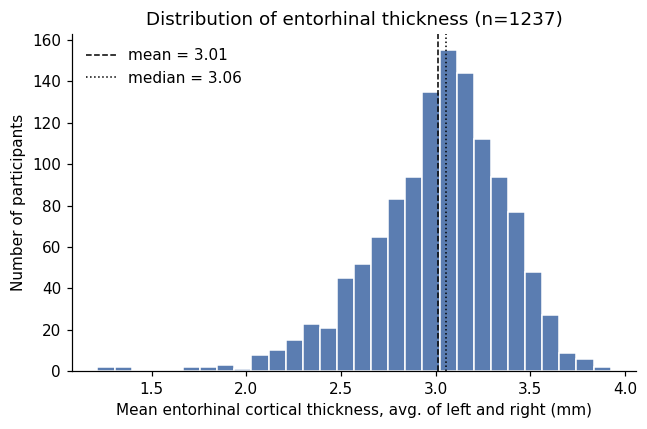

In [32]:
COL = {"Normal cognition": "#4C9F70", "MCI": "#E0A030", "Dementia": "#C0504D"}

# شکل ۱: هیستوگرام ضخامت
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df.ENT_TH, bins=30, color="#5B7DB1", edgecolor="white")
ax.axvline(df.ENT_TH.mean(), color="k", ls="--", lw=1, label=f"mean = {df.ENT_TH.mean():.2f}")
ax.axvline(df.ENT_TH.median(), color="k", ls=":", lw=1, label=f"median = {df.ENT_TH.median():.2f}")
ax.set(xlabel="Mean entorhinal cortical thickness, avg. of left and right (mm)",
       ylabel="Number of participants", title=f"Distribution of entorhinal thickness (n={len(df)})")
ax.legend(frameon=False); fig.tight_layout()
fig.savefig(f"{OUT_DIR}/figures/fig1_hist_entorhinal_thickness.png"); plt.show()

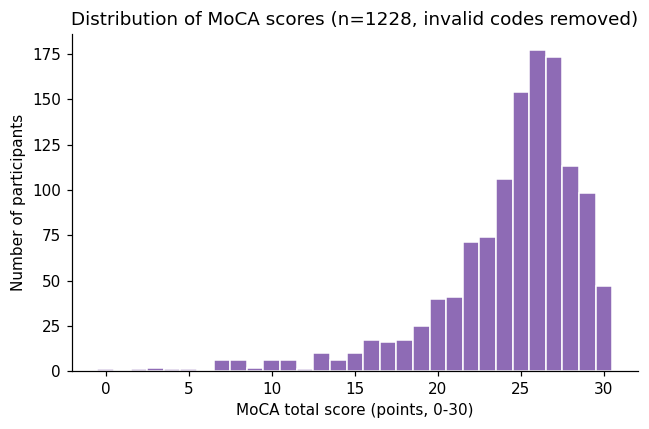

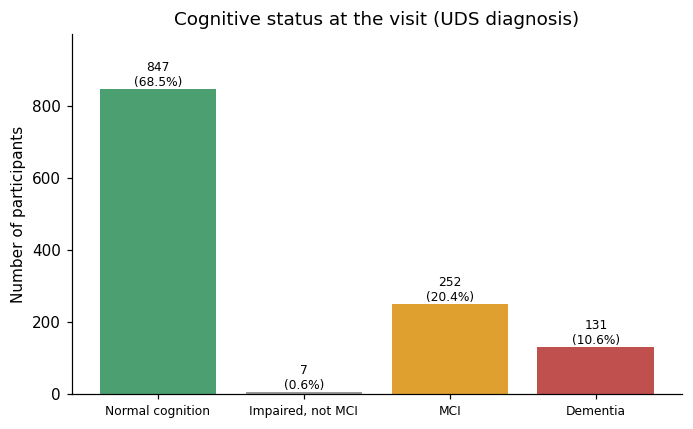

In [33]:
# شکل ۲: هیستوگرام MoCA
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df.MOCA.dropna(), bins=np.arange(-0.5, 31.5, 1), color="#8E6BB5", edgecolor="white")
ax.set(xlabel="MoCA total score (points, 0-30)", ylabel="Number of participants",
       title=f"Distribution of MoCA scores (n={df.MOCA.notna().sum()}, invalid codes removed)")
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/fig2_hist_moca.png"); plt.show()

# شکل ۳: میله‌ای وضعیت شناختی
fig, ax = plt.subplots(figsize=(6.4, 4))
cnt = df.GROUP.value_counts().reindex(list(GROUP_LABELS.values()))
bars = ax.bar(cnt.index, cnt.values, color=["#4C9F70", "#999999", "#E0A030", "#C0504D"])
for b, v in zip(bars, cnt.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 8, f"{v}\n({100 * v / cnt.sum():.1f}%)", ha="center", fontsize=8)
ax.set(ylabel="Number of participants", title="Cognitive status at the visit (UDS diagnosis)", ylim=(0, cnt.max() * 1.18))
ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/fig3_bar_cognitive_status.png"); plt.show()

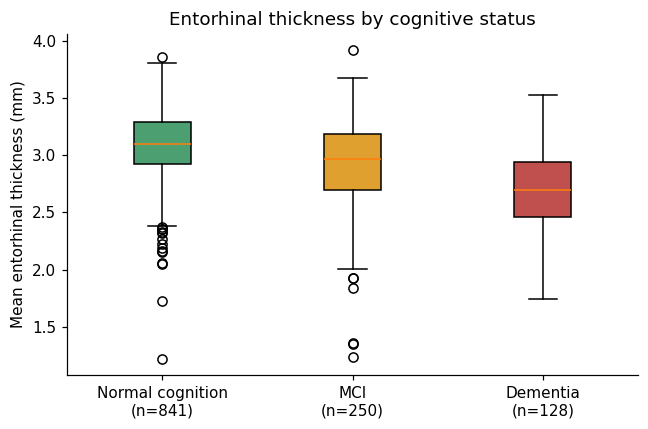

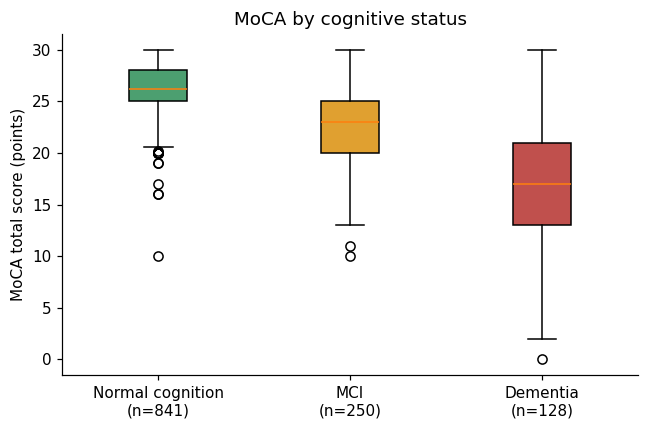

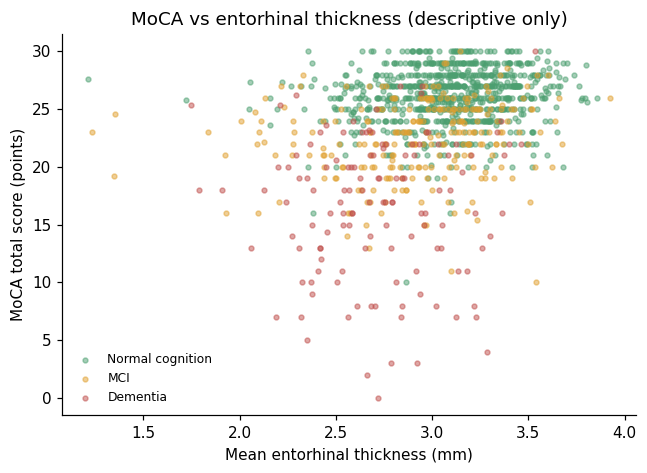

In [34]:
# شکل ۴ و ۵: جعبه‌ای به تفکیک گروه
def box(var, ylabel, title, fname):
    fig, ax = plt.subplots(figsize=(6, 4))
    data = [main.loc[main.GROUP == k, var] for k in MAIN_GROUPS]
    bp = ax.boxplot(data, tick_labels=[f"{k}\n(n={len(d)})" for k, d in zip(MAIN_GROUPS, data)], patch_artist=True)
    for p, k in zip(bp["boxes"], MAIN_GROUPS):
        p.set_facecolor(COL[k])
    ax.set(ylabel=ylabel, title=title)
    fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/{fname}"); plt.show()

box("ENT_TH", "Mean entorhinal thickness (mm)", "Entorhinal thickness by cognitive status", "fig4_box_thickness_by_group.png")
box("MOCA", "MoCA total score (points)", "MoCA by cognitive status", "fig5_box_moca_by_group.png")

# شکل ۶: پراکنش (فقط توصیفی)
fig, ax = plt.subplots(figsize=(6, 4.4))
for k in MAIN_GROUPS:
    s = main[main.GROUP == k]
    ax.scatter(s.ENT_TH, s.MOCA, s=10, alpha=.5, color=COL[k], label=k)
ax.set(xlabel="Mean entorhinal thickness (mm)", ylabel="MoCA total score (points)", title="MoCA vs entorhinal thickness (descriptive only)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT_DIR}/figures/fig6_scatter_thickness_moca.png"); plt.show()

## ۹. مقایسه‌ی توصیفی گروه‌ها (تکلیف ۹) — بدون هیچ ادعای استنباطی

In [35]:
g = main.groupby("GROUP")
cmp_ = pd.concat({
    "n": g.size(),
    "age_mean": g.NACCAGE.mean(), "age_sd": g.NACCAGE.std(),
    "pct_female": g.SEX.apply(lambda s: 100 * (s == 2).mean()),
    "edu_mean": g.EDU.mean(),
    "moca_mean": g.MOCA.mean(), "moca_median": g.MOCA.median(), "moca_sd": g.MOCA.std(),
    "entTH_mean": g.ENT_TH.mean(), "entTH_median": g.ENT_TH.median(), "entTH_sd": g.ENT_TH.std(),
}, axis=1).loc[MAIN_GROUPS].round(2)
display(cmp_)
cmp_.to_csv(f"{OUT_DIR}/tables/07_group_comparison_descriptive.csv")

,n,age_mean,age_sd,pct_female,edu_mean,moca_mean,moca_median,moca_sd,entTH_mean,entTH_median,entTH_sd
GROUP,,,,,,,,,,,
Normal cognition,841,67.25,7.94,64.33,16.37,26.18,26.2,2.36,3.09,3.10,0.30
MCI,250,70.84,7.46,44.00,16.10,22.40,23.0,3.38,2.91,2.97,0.41
Dementia,128,68.99,8.98,60.94,15.81,16.48,17.0,6.10,2.72,2.70,0.35


In [36]:
g = main.groupby("GROUP")
cmp_ = pd.concat({
    "n": g.size(),
    "age_mean": g.NACCAGE.mean(), "age_sd": g.NACCAGE.std(),
    "pct_female": g.SEX.apply(lambda s: 100 * (s == 2).mean()),
    "edu_mean": g.EDU.mean(),
    "moca_mean": g.MOCA.mean(), "moca_sd": g.MOCA.std(), "moca_median": g.MOCA.median(),
    "entTH_mean": g.ENT_TH.mean(), "entTH_sd": g.ENT_TH.std(), "entTH_median": g.ENT_TH.median(),
}, axis=1).loc[MAIN_GROUPS].round(2)

display(cmp_)
cmp_.to_csv(f"{OUT_DIR}/tables/07_group_comparison_descriptive.csv")

,n,age_mean,age_sd,pct_female,edu_mean,moca_mean,moca_sd,moca_median,entTH_mean,entTH_sd,entTH_median
GROUP,,,,,,,,,,,
Normal cognition,841,67.25,7.94,64.33,16.37,26.18,2.36,26.2,3.09,0.30,3.10
MCI,250,70.84,7.46,44.00,16.10,22.40,3.38,23.0,2.91,0.41,2.97
Dementia,128,68.99,8.98,60.94,15.81,16.48,6.10,17.0,2.72,0.35,2.70


## ۱۰. خلاصه‌ی مشترک شناختی و تصویربرداری (ج.۵) و نقاط غیرعادی

In [37]:
print("پایین‌ترین ضخامت‌های انتورینال در کل فایل:")
low_th = df.nsmallest(8, "ENT_TH")[["NACCID", "GROUP", "NACCAGE", "MOCA", "ENT_TH"]].round(2)
display(low_th)
low_th.to_csv(f"{OUT_DIR}/tables/08_lowest_entorhinal_thickness.csv", index=False)

print("\nپایین‌ترین نمرات MoCA در کل فایل:")
low_moca = df.nsmallest(8, "MOCA")[["NACCID", "GROUP", "NACCAGE", "MOCA", "ENT_TH"]].round(2)
display(low_moca)
low_moca.to_csv(f"{OUT_DIR}/tables/09_lowest_moca_scores.csv", index=False)

پایین‌ترین ضخامت‌های انتورینال در کل فایل:


,NACCID,GROUP,NACCAGE,MOCA,ENT_TH
518,NACC931831,Normal cognition,61.0,27.6,1.21
484,NACC733852,MCI,75.0,23.0,1.24
1058,NACC868474,MCI,69.0,19.2,1.35
494,NACC823780,MCI,60.0,24.6,1.36
388,NACC176148,Normal cognition,71.0,25.8,1.72
365,NACC012224,Dementia,69.0,25.4,1.75
449,NACC525648,Dementia,76.0,18.0,1.79
939,NACC065708,MCI,70.0,23.0,1.84



پایین‌ترین نمرات MoCA در کل فایل:


,NACCID,GROUP,NACCAGE,MOCA,ENT_TH
707,NACC235322,Dementia,59.0,0.0,2.72
414,NACC315847,Dementia,56.0,2.0,2.66
403,NACC238162,Dementia,63.0,3.0,2.92
407,NACC261988,Dementia,57.0,3.0,2.79
501,NACC859406,Dementia,64.0,4.0,3.28
412,NACC291903,Dementia,58.0,5.0,2.35
326,NACC569086,Dementia,67.0,7.0,2.32
356,NACC892008,Dementia,64.0,7.0,2.56


In [38]:
dementia_high_moca = int(((df.NACCUDSD == 4) & (df.MOCA >= 24)).sum())
normal_low_moca = int(((df.NACCUDSD == 1) & (df.MOCA < 18)).sum())

print(f"تعداد افراد دمانس با MoCA بالای ۲۴: {dementia_high_moca}")
print(f"تعداد افراد نرمال با MoCA پایین ۱۸: {normal_low_moca}")

تعداد افراد دمانس با MoCA بالای ۲۴: 10
تعداد افراد نرمال با MoCA پایین ۱۸: 4


In [39]:
inconsistent_normal = int(((df.NACCUDSD == 1) & (df.CDRGLOB >= 1)).sum())
inconsistent_dementia = int(((df.NACCUDSD == 4) & (df.CDRGLOB == 0)).sum())

print(f"تعداد افراد نرمال با CDR >= 1: {inconsistent_normal}")
print(f"تعداد افراد دمانس با CDR == 0: {inconsistent_dementia}")

تعداد افراد نرمال با CDR >= 1: 0
تعداد افراد دمانس با CDR == 0: 0


## ۱۱. ذخیره‌ی خروجی‌ها

In [40]:
import shutil
shutil.make_archive("phase1_outputs", "zip", OUT_DIR)
print("ساخته شد: phase1_outputs.zip")
try:
    from google.colab import files
    files.download("phase1_outputs.zip")
except ImportError:
    pass

ساخته شد: phase1_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>